# Bài 2 (Trang 28) - Dữ liệu Bank Marketing
## Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và khả năng đăng ký (y)

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

df = pd.read_csv("../Dataset/bank/bank.csv", sep=";")

### Các bước xử lý của câu 1 → 2 (chuẩn bị dữ liệu)

In [3]:
# Trong bộ dữ liệu, giá trị thiếu được ghi là 'unknown' -> chuyển về NaN
df = df.replace("unknown", np.nan)

### Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và khả năng đăng ký (y)

In [4]:
df["subscribed"] = (df["y"] == "yes").astype(int)

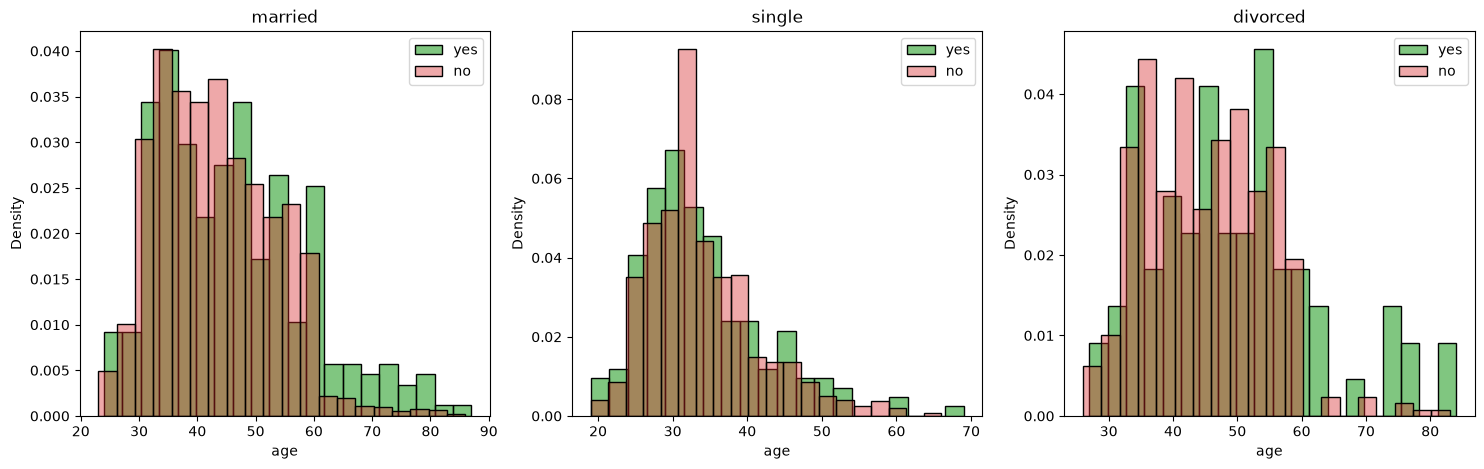

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
for ax, m in zip(axes, ["married", "single", "divorced"]):
    sub = df[df["marital"] == m]
    sns.histplot(sub[sub["subscribed"] == 1]["age"], bins=20, label="yes", ax=ax, color="tab:green", alpha=0.6, stat="density")
    sns.histplot(sub[sub["subscribed"] == 0]["age"], bins=20, label="no", ax=ax, color="tab:red", alpha=0.4, stat="density")
    ax.set_title(m)
    ax.legend()
plt.show()

In [6]:
age_bins = pd.cut(df["age"], bins=[17, 25, 30, 40, 50, 60, 100])
df.pivot_table(index=age_bins, columns="marital", values="subscribed", aggfunc="mean", observed=False).round(3)

marital,divorced,married,single
age,,,
"(17, 25]",NaN,0.160,0.221
"(25, 30]",0.133,0.075,0.153
"(30, 40]",0.117,0.090,0.112
"(40, 50]",0.130,0.090,0.161
"(50, 60]",0.139,0.091,0.146
"(60, 100]",0.545,0.343,0.333


### Nhận xét
- Khách hàng trên 60 tuổi có tỷ lệ đăng ký cao nhất (33-55%), khách hàng trẻ dưới 25 tuổi cũng đăng ký khá cao (16-22%).
- Nhóm 30-50 tuổi có tỷ lệ đăng ký thấp nhất (~9-16%).
- Người độc thân (single) và ly hôn (divorced) có xu hướng đăng ký cao hơn người đã kết hôn (married) ở hầu hết các lứa tuổi.